# Experimento Preditivo de Redes (Horizonte $t + 12$ minutos)

Este notebook realiza a construção do dataset preditivo para $t + 12$ minutos e treina/avalia os modelos preditivos (Árvore de Decisão, Random Forest e XGBoost) utilizando divisão temporal estrita ($70\%$ Treino, $15\%$ Validação e $15\%$ Teste Cego).

## Etapa 1: Geração do Dataset Preditivo de 12 Minutos (`t12`)

In [18]:
import itertools
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
from joblib import dump
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_sample_weight

SEED = 42

# Configuração visual do Matplotlib e Seaborn
plt.style.use(
    "seaborn-v0_8-whitegrid"
    if "seaborn-v0_8-whitegrid" in plt.style.available
    else "default"
)

# Localização dinâmica da raiz do repositório (project-redes)
current_dir = Path.cwd()
project_root = current_dir
for parent in [current_dir, *current_dir.parents]:
    if (parent / "metadados").exists():
        project_root = parent
        break

# Diretórios de saída para artefatos e imagens preditivas
PRED_DIR = project_root / "predicao_12min"
PRED_IMG_DIR = PRED_DIR / "imagens"
PRED_MODELS_DIR = PRED_DIR / "modelos"

PRED_IMG_DIR.mkdir(parents=True, exist_ok=True)
PRED_MODELS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Raiz do projeto identificada em: {project_root}")
print(f"As imagens serão salvas em: {PRED_IMG_DIR}")
print(f"Os modelos serão salvos em: {PRED_MODELS_DIR}")

Raiz do projeto identificada em: c:\Users\vinic\OneDrive\Documentos\project-redes
As imagens serão salvas em: c:\Users\vinic\OneDrive\Documentos\project-redes\predicao_12min\imagens
Os modelos serão salvos em: c:\Users\vinic\OneDrive\Documentos\project-redes\predicao_12min\modelos


## Etapa 2: Treinamento, Avaliação e Comparação dos Modelos Preditivos

In [19]:
# Caminho para o dataset preditivo rotulado em t+12 min
NOME_DATASET = "dataset_preditivo_t12_v1.csv"
CANDIDATOS = [
    project_root / "metadados" / "preditivo" / NOME_DATASET,
    project_root / "metadados" / NOME_DATASET,
    project_root / "metadados" / "etapa 2" / NOME_DATASET,
]
DATASET_PATH = next((p for p in CANDIDATOS if p.exists()), None)
if DATASET_PATH is None:
    raise FileNotFoundError(
        "Dataset não encontrado. Caminhos testados:\n"
        + "\n".join(f"  - {p}" for p in CANDIDATOS)
    )

df = pd.read_csv(DATASET_PATH)

# Atributos preditivos (medidos no instante t)
FEATURES = [
    "z_robusto",
    "aumento_pct",
    "jitter_relativo",
    "perda_pct",
    "timeout_atual",
    "n5_timeout",
    "n5_aumento80",
    "n5_risco",
]

# Coluna alvo (estado da rede em t + 12 min) e coluna de split temporal
TARGET = "alvo_classe_t12_v1" if "alvo_classe_t12_v1" in df.columns else "classe"
SPLIT_COL = (
    "split_temporal_v1" if "split_temporal_v1" in df.columns else "split_temporal"
)

faltando = [c for c in [*FEATURES, TARGET, SPLIT_COL] if c not in df.columns]
if faltando:
    raise KeyError(f"Colunas ausentes no dataset: {faltando}")

# Classes (a ordem define as linhas/colunas das matrizes de confusão)
CLASSES = ["OK", "RISCO", "FALHA"]
desconhecidas = set(df[TARGET].dropna().unique()) - set(CLASSES)
if desconhecidas:
    raise ValueError(f"Classes inesperadas no alvo: {desconhecidas}")
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}

# Valores ausentes: Árvore/Floresta recebem imputação pela mediana (se houver
# NaN); o XGBoost lida com NaN nativamente.
HAS_NAN = bool(df[FEATURES].isna().any().any())

# Separação das partições
train_mask = df[SPLIT_COL] == "treino"
val_mask = df[SPLIT_COL] == "validacao"
test_mask = df[SPLIT_COL] == "teste"

X_train, y_train = df.loc[train_mask, FEATURES], df.loc[train_mask, TARGET]
X_val, y_val = df.loc[val_mask, FEATURES], df.loc[val_mask, TARGET]
X_test, y_test = df.loc[test_mask, FEATURES], df.loc[test_mask, TARGET]

if min(len(X_train), len(X_val), len(X_test)) == 0:
    raise ValueError("Treino, validação e teste precisam ser não vazios.")

print("Dataset preditivo carregado com sucesso!")
print(f"  Arquivo: {DATASET_PATH}")
print(f"  • Treino:    {len(X_train):>6} amostras ({len(X_train)/len(df)*100:.1f}%)")
print(f"  • Validação: {len(X_val):>6} amostras ({len(X_val)/len(df)*100:.1f}%)")
print(f"  • Teste:     {len(X_test):>6} amostras ({len(X_test)/len(df)*100:.1f}%)")
print(f"  • Valores ausentes nas features: {'sim' if HAS_NAN else 'não'}")

Dataset preditivo carregado com sucesso!
  Arquivo: c:\Users\vinic\OneDrive\Documentos\project-redes\metadados\preditivo\dataset_preditivo_t12_v1.csv
  • Treino:     71096 amostras (70.2%)
  • Validação:  15124 amostras (14.9%)
  • Teste:      15052 amostras (14.9%)
  • Valores ausentes nas features: sim


In [20]:
def metricas(y_true, y_pred):
    """Métricas usadas na comparação (FALHA é a classe de interesse)."""
    kw = dict(labels=["FALHA"], average=None, zero_division=0)
    return {
        "f1_macro": float(
            f1_score(y_true, y_pred, labels=CLASSES, average="macro", zero_division=0)
        ),
        "acuracia": float(accuracy_score(y_true, y_pred)),
        "recall_falha": float(recall_score(y_true, y_pred, **kw)[0]),
        "precision_falha": float(precision_score(y_true, y_pred, **kw)[0]),
    }


def rank_de(registro):
    """Critério de seleção: Macro F1; desempate pelo Recall de FALHA."""
    return (registro["f1_macro"], registro["recall_falha"])


def criar_modelo(nome, params):
    if nome == "arvore_decisao":
        modelo = DecisionTreeClassifier(random_state=SEED, **params)
        return make_pipeline(SimpleImputer(strategy="median"), modelo) if HAS_NAN else modelo
    if nome == "random_forest":
        modelo = RandomForestClassifier(
            max_features="sqrt", random_state=SEED, n_jobs=-1, **params
        )
        return make_pipeline(SimpleImputer(strategy="median"), modelo) if HAS_NAN else modelo
    return xgb.XGBClassifier(
        objective="multi:softprob",
        eval_metric="mlogloss",
        tree_method="hist",
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        n_jobs=4,
        random_state=SEED,
        **params,
    )


def treinar(nome, params):
    """Treina um modelo e devolve (modelo, tempo de treino em segundos)."""
    params = dict(params)
    peso_balanceado = params.pop("peso_balanceado", False)
    modelo = criar_modelo(nome, params)

    t0 = time.perf_counter()
    if nome == "xgboost":
        # XGBoost exige rótulos inteiros 0..n-1
        y_enc = y_train.map(CLASS_TO_IDX).to_numpy()
        fit_kw = {}
        if peso_balanceado:
            fit_kw["sample_weight"] = compute_sample_weight("balanced", y_train)
        modelo.fit(X_train, y_enc, **fit_kw)
    else:
        modelo.fit(X_train, y_train)
    return modelo, time.perf_counter() - t0


def prever(nome, modelo, X):
    """Devolve sempre rótulos de texto (OK/RISCO/FALHA)."""
    pred = modelo.predict(X)
    if nome == "xgboost":
        return np.array(CLASSES)[np.asarray(pred).astype(int)]
    return pred


def expandir(grade):
    chaves = list(grade)
    for valores in itertools.product(*grade.values()):
        yield dict(zip(chaves, valores))


GRADES = {
    "arvore_decisao": {
        "criterion": ("gini", "entropy"),
        "max_depth": (4, 6, 10, None),
        "min_samples_leaf": (5, 20, 100),
        "class_weight": (None, "balanced"),
    },
    "random_forest": {
        "n_estimators": (100, 200),
        "max_depth": (10, None),
        "min_samples_leaf": (20, 100),
        "class_weight": (None, "balanced_subsample"),
    },
    "xgboost": {
        "n_estimators": (100, 200),
        "max_depth": (3, 5),
        "learning_rate": (0.05, 0.1),
        "min_child_weight": (1, 5),
        "peso_balanceado": (False, True),
    },
}

grid_results = []
melhores = {}

for nome, grade in GRADES.items():
    combinacoes = list(expandir(grade))
    print(f"{nome}: testando {len(combinacoes)} combinações...")
    for params in combinacoes:
        modelo, t_treino = treinar(nome, params)
        registro = {
            "modelo": nome,
            "parametros": params,
            "tempo_treino_s": t_treino,
            **metricas(y_val, prever(nome, modelo, X_val)),
        }
        grid_results.append(registro)
        if nome not in melhores or rank_de(registro) > rank_de(melhores[nome]["registro"]):
            melhores[nome] = {"registro": registro, "modelo": modelo}

with open(PRED_DIR / "grid_search_t12_validacao.json", "w", encoding="utf-8") as f:
    json.dump(grid_results, f, ensure_ascii=False, indent=2)

print("\nMelhores hiperparâmetros (escolhidos na validação):")
for nome, item in melhores.items():
    print(f"  • {nome}: {item['registro']['parametros']}")

arvore_decisao: testando 48 combinações...
random_forest: testando 16 combinações...
xgboost: testando 32 combinações...

Melhores hiperparâmetros (escolhidos na validação):
  • arvore_decisao: {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 100, 'class_weight': None}
  • random_forest: {'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 20, 'class_weight': None}
  • xgboost: {'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1, 'min_child_weight': 1, 'peso_balanceado': False}


In [21]:
PARTICOES = {
    "validacao": (X_val, y_val, val_mask),
    "teste": (X_test, y_test, test_mask),
}
resultados = {"validacao": {}, "teste": {}}

# Baseline de persistência: prever em t+12 o estado medido em t
COL_ESTADO_ATUAL = next(
    (c for c in ("baseline_persistencia_v1", "classe") if c in df.columns and c != TARGET),
    None,
)

# A) Majoritária e B) Persistência
classe_majoritaria = y_train.mode()[0]

for particao, (X_p, y_p, mask_p) in PARTICOES.items():
    y_pred_maj = np.full(shape=len(y_p), fill_value=classe_majoritaria)
    resultados[particao]["baseline_majoritaria"] = {
        **metricas(y_p, y_pred_maj),
        "tempo_treino_s": 0.0,
        "latencia_ms": 0.0,
    }
    if COL_ESTADO_ATUAL:
        y_pred_pers = df.loc[mask_p, COL_ESTADO_ATUAL]
        resultados[particao]["baseline_persistencia"] = {
            **metricas(y_p, y_pred_pers),
            "tempo_treino_s": 0.0,
            "latencia_ms": 0.0,
        }

if COL_ESTADO_ATUAL is None:
    print("Aviso: coluna de persistência não encontrada; baseline ignorada.")
print(f"Baselines avaliadas com sucesso! (classe majoritária: {classe_majoritaria})")

Baselines avaliadas com sucesso! (classe majoritária: OK)


In [22]:
for nome, item in melhores.items():
    modelo = item["modelo"]
    print(f"Avaliando: {nome}...")
    for particao, (X_p, y_p, _) in PARTICOES.items():
        # Latência de inferência por amostra (ms)
        t0 = time.perf_counter()
        y_pred = prever(nome, modelo, X_p)
        latencia_ms = (time.perf_counter() - t0) / len(X_p) * 1000

        resultados[particao][nome] = {
            **metricas(y_p, y_pred),
            "tempo_treino_s": item["registro"]["tempo_treino_s"],
            "latencia_ms": latencia_ms,
        }

    # Artefato individual do modelo treinado (.joblib)
    dump(modelo, PRED_MODELS_DIR / f"{nome}_t12.joblib")

# Pacote único com metadados (o XGBoost prevê índices: classes[indice])
pacote = {
    "status": "experimental_preditivo_t12",
    "features": FEATURES,
    "classes": CLASSES,
    "modelos": {n: i["modelo"] for n, i in melhores.items()},
    "melhores_parametros": {n: i["registro"]["parametros"] for n, i in melhores.items()},
}
dump(pacote, PRED_MODELS_DIR / "pacote_modelos_t12.joblib", compress=3)

with open(PRED_DIR / "resultados_t12.json", "w", encoding="utf-8") as f:
    json.dump(resultados, f, ensure_ascii=False, indent=2)

print("\nTodos os modelos foram avaliados e salvos!")

Avaliando: arvore_decisao...
Avaliando: random_forest...
Avaliando: xgboost...

Todos os modelos foram avaliados e salvos!


In [23]:
def imprimir_tabela(titulo, dados):
    larg = 115
    print("=" * larg)
    print(f"{titulo:^{larg}}")
    print("=" * larg)
    cab_lat = "Latência (ms)"
    print(
        f"{'Modelo Preditivo':<24} | {'Macro F1':<8} | {'Acurácia':<8} | "
        f"{'Recall FALHA':<12} | {'Precision FALHA':<15} | "
        f"{'Treino (s)':<10} | {cab_lat:<12}"
    )
    print("-" * larg)
    for nome, m in dados.items():
        print(
            f"{nome:<24} | {m['f1_macro']:<8.4f} | {m['acuracia']*100:>6.2f}%  |"
            f" {m['recall_falha']:<12.4f} | {m['precision_falha']:<15.4f} |"
            f" {m['tempo_treino_s']:>8.2f}s | {m['latencia_ms']:>9.4f}ms"
        )
    print("=" * larg)


imprimir_tabela(
    "--- MELHORES MODELOS NA VALIDAÇÃO (t + 12 min) ---", resultados["validacao"]
)
print()
imprimir_tabela(
    "--- DESEMPENHO FINAL NO TESTE CEGO (t + 12 min) ---", resultados["teste"]
)

                                --- MELHORES MODELOS NA VALIDAÇÃO (t + 12 min) ---                                 
Modelo Preditivo         | Macro F1 | Acurácia | Recall FALHA | Precision FALHA | Treino (s) | Latência (ms)
-------------------------------------------------------------------------------------------------------------------
baseline_majoritaria     | 0.3010   |  82.31%  | 0.0000       | 0.0000          |     0.00s |    0.0000ms
baseline_persistencia    | 0.7049   |  89.02%  | 0.7265       | 0.7272          |     0.00s |    0.0000ms
arvore_decisao           | 0.7436   |  92.09%  | 0.6621       | 0.9276          |     0.41s |    0.0006ms
random_forest            | 0.7446   |  92.06%  | 0.6447       | 0.9417          |     1.58s |    0.0060ms
xgboost                  | 0.7525   |  92.39%  | 0.6753       | 0.9368          |     3.52s |    0.0045ms

                                --- DESEMPENHO FINAL NO TESTE CEGO (t + 12 min) ---                                
Modelo Predi

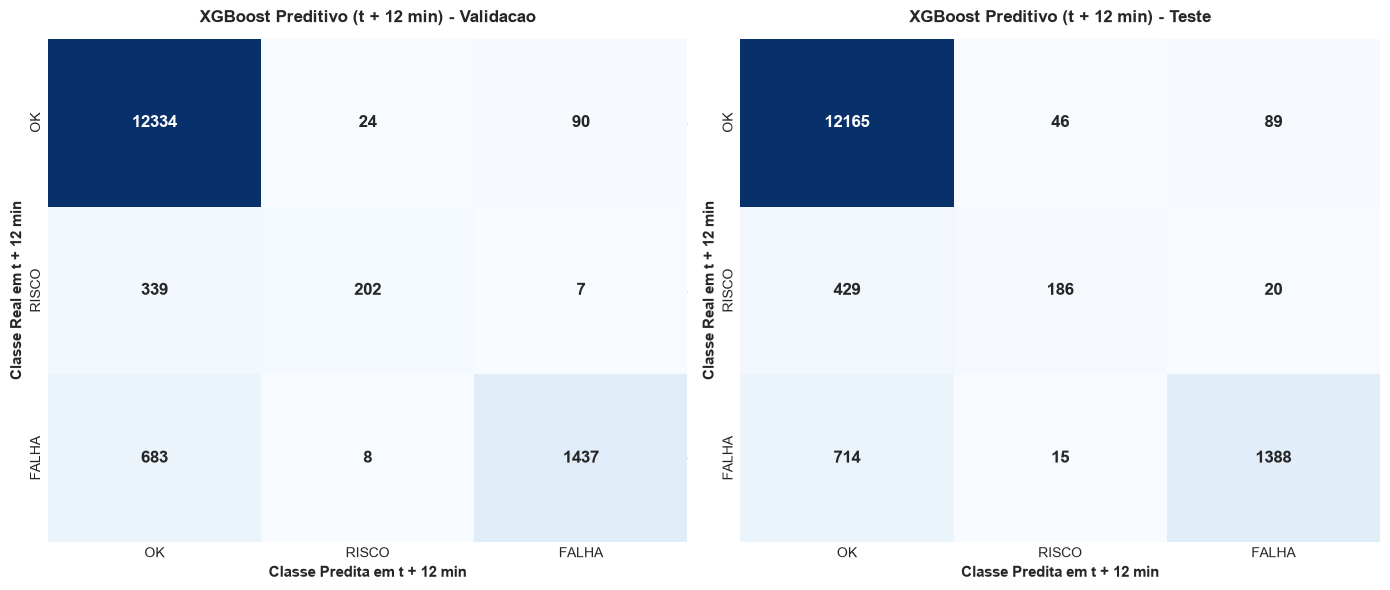

Matriz de confusão salva em: c:\Users\vinic\OneDrive\Documentos\project-redes\predicao_12min\imagens\matriz_confusao_xgboost_t12.png


In [24]:
# Matriz de confusão do XGBoost (validação e teste cego)
xgb_model = melhores["xgboost"]["modelo"]

fig, eixos = plt.subplots(1, 2, figsize=(14, 6))
for eixo, (particao, (X_p, y_p, _)) in zip(eixos, PARTICOES.items()):
    y_pred_xgb = prever("xgboost", xgb_model, X_p)
    cm = confusion_matrix(y_p, y_pred_xgb, labels=CLASSES)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASSES,
        yticklabels=CLASSES,
        cbar=False,
        annot_kws={"size": 12, "weight": "bold"},
        ax=eixo,
    )
    eixo.set_title(
        f"XGBoost Preditivo (t + 12 min) - {particao.capitalize()}",
        fontsize=12,
        fontweight="bold",
        pad=12,
    )
    eixo.set_xlabel("Classe Predita em t + 12 min", fontsize=11, fontweight="bold")
    eixo.set_ylabel("Classe Real em t + 12 min", fontsize=11, fontweight="bold")

plt.tight_layout()
cm_out_path = PRED_IMG_DIR / "matriz_confusao_xgboost_t12.png"
plt.savefig(cm_out_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Matriz de confusão salva em: {cm_out_path}")